# 03 对照组：EKF 3σ 裕度安全滤波、纯 INS 推算 + 安全滤波

三种方法共用**同一个**预测安全滤波器（备份策略预测、入口逐航速认证、桥下平滑混合、同一组参数），
在同一批随机世界（与 01 完全相同的种子和场景）上运行，只改“导航误差管”这一项：

| 方法 | 导航 | 安全滤波使用的误差管 |
|---|---|---|
| 本文（filter） | 船模辅助推算 + GNSS 固定增益融合 | 确定性误差盒：各误差源最坏情况线性相加 |
| EKF 3σ（ekf3s） | 同上 | 同一导航器误差的 EKF 式协方差，取 3σ |
| 纯 INS（ins / ins_1mg） | 陀螺 + 加速度计积分，不用船模、转速、海图 | INS 确定性误差盒（加速度零偏二次增长，与海流无关） |

**EKF 3σ 的构造**（`bridge_sim/ext.py: GaussianBound`）：误差状态 [δN, δE, δψ, 纵/横速度误差, 背景流误差 N/E,
射流幅值误差, 陀螺零偏]，后六项为随机常值。每个误差源的大小与确定性误差盒完全相同，按常用的
“声明界 = 3σ”约定取 σ = 界/3；GNSS 融合按导航器实际使用的固定增益做 Joseph 形式更新，所以协方差与实际运行的导航器一致。
与误差盒的区别只有三点：误差源按平方和开根（RSS）合成而非线性相加；射流形状取估计位置处的值而非北向区间内最大值；梯度项用局部梯度。
它代表“用标准高斯导航完好性做安全裕度”的做法，同样的信息，不同的合成方式。

**纯 INS 的构造**：加速度计输出真实速度增量 + 体轴常值零偏（场景内在 ±声明界内均匀抽取）+ 均匀噪声；
声明界：零偏 2 mg（低成本 MEMS 经 GNSS 标定后的量级，含约 1 mrad 倾角误差）或 1 mg，噪声 0.002 m/s²，
最大水平加速度 1.2 m/s²（制动/后撤之外实测最大 1.09）。速度界线性增长、位置界二次增长，与海流无关。
滤波器的预测模型仍用船模和已知海流，所以 INS 导航下“预测 = 估计”不再自动成立，A3 需由认证丢失率检验。

In [1]:
import sys, time
from pathlib import Path
from dataclasses import replace
ROOT = Path.cwd(); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from bridge_sim.ext import sample_scenario, run_batch, pmap, ins_gate, gate_check, DEFAULT_SCENARIO
from bridge_sim.metrics import rates_table, fmt_table, feasible, covered, METHOD_BUDGET

RES = ROOT/'results'; RES.mkdir(exist_ok=True)
FIG = ROOT/'figures'; FIG.mkdir(exist_ok=True)
WORKERS = 4
N_MAIN, N_RAND = 200, 240
BASELINES = ('ekf3s', 'ins', 'ins_1mg')
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 60)

# identical generators to 01_monte_carlo.ipynb (checked against its CSV below)
def main_scenarios():
    rng = np.random.default_rng(2026)
    return [sample_scenario(rng, 10000 + i, length=19.0, width=8.0) for i in range(N_MAIN)]

def random_length_scenarios():
    rng = np.random.default_rng(2027)
    out = []
    for i in range(N_RAND):
        L = float(rng.uniform(15.0, 50.0))
        out.append(sample_scenario(rng, 20000 + i, length=round(L, 2), width=8.0))
    return out

def cached(path, scenarios, methods):
    if path.exists():
        print('loading', path.name); return pd.read_csv(path)
    t0 = time.time()
    df = pd.DataFrame(run_batch(scenarios, methods, workers=WORKERS, log_path=str(RES/'progress.log')))
    df.to_csv(path, index=False); print(f'{path.name}: {len(df)} scenarios in {time.time()-t0:.0f} s')
    return df

def merged(mc_path, base_path, scenarios):
    mc = pd.read_csv(mc_path)
    bl = cached(base_path, scenarios, BASELINES)
    assert 'error' not in bl or bl['error'].isna().all()
    assert (mc['seed'].values == bl['seed'].values).all() and np.allclose(mc['length'], bl['length'])
    keep = [c for c in bl.columns if c.startswith(BASELINES)]
    return pd.concat([mc, bl[keep]], axis=1)

In [2]:
A = merged(RES/'mc_main_bridge.csv', RES/'baselines_main_bridge.csv', main_scenarios())
B = merged(RES/'mc_random_length.csv', RES/'baselines_random_length.csv', random_length_scenarios())
tabs = []
for part, df in (('A: 8x19 m', A), ('B: 8 m, L~U[15,50]', B)):
    for thr in (0.0, METHOD_BUDGET):
        t = rates_table(df, ['filter', *BASELINES], thr); t.insert(0, 'part', part); tabs.append(t)
cmp = pd.concat(tabs, ignore_index=True)
cmp.to_csv(RES/'baselines_summary.csv', index=False)
wide = cmp[cmp.threshold_m == 0].pivot_table(index=['part', 'metric'], columns='method', values='rate', sort=False)
(100*wide[['filter', *BASELINES]]).round(1)

loading baselines_main_bridge.csv
loading baselines_random_length.csv


method                                                               filter  ekf3s    ins  ins_1mg
part               metric                                                                         
A: 8x19 m          accept (放行率)                                       100.0  100.0    0.0    100.0
                   pass (通过率)                                         100.0  100.0    0.0     94.5
                   collision (撞墙率)                                      0.0    0.0    0.0      0.0
                   false accept: admitted & collided (错误放行, 按放行数)       0.0    0.0    NaN      0.0
                   false accept: admitted & infeasible (错误放行, 按放行数)     0.0    0.0    NaN      0.0
                   false reject (误拒, 按能过数)                              0.0    0.0  100.0      0.0
                   bound coverage (误差界覆盖率, 全程)                        100.0    0.0  100.0    100.0
                   certification loss (认证丢失, 按放行数)                      0.0    0.0    NaN      5.5
                   feasible (能过比例)                                    100.0  100.0  100.0    100.0
B: 8 m, L~U[15,50] accept (放行率)                                        14.6   59.6    3.3     13.8
                   pass (通过率)                                          14.6   59.6    0.8     12.5
                   collision (撞墙率)                                      0.0    0.0    0.0      0.0
                   false accept: admitted & collided (错误放行, 按放行数)       0.0    0.0    0.0      0.0
                   false accept: admitted & infeasible (错误放行, 按放行数)     0.0    0.0    0.0      0.0
                   false reject (误拒, 按能过数)                             85.2   39.7   96.6     86.1
                   bound coverage (误差界覆盖率, 全程)                        100.0    0.0  100.0    100.0
                   certification loss (认证丢失, 按放行数)                      0.0    0.0   75.0      9.1
                   feasible (能过比例)                                     98.8   98.8   98.8     98.8

In [3]:
# counts with 95% CI for the safety-relevant rows
key = ['false accept: admitted & collided (错误放行, 按放行数)', 'collision (撞墙率)',
       'bound coverage (误差界覆盖率, 全程)', 'certification loss (认证丢失, 按放行数)', 'false reject (误拒, 按能过数)']
fmt_table(cmp[(cmp.threshold_m == 0) & cmp.metric.isin(key)]).sort_values(['part', 'metric', 'method'])

,part,method,metric,threshold_m,rate,95% CI,k/n
15,A: 8x19 m,ekf3s,"bound coverage (误差界覆盖率, 全程)",0.0,0.0%,"[0.0, 1.9]%",0/200
6,A: 8x19 m,filter,"bound coverage (误差界覆盖率, 全程)",0.0,100.0%,"[98.1, 100.0]%",200/200
24,A: 8x19 m,ins,"bound coverage (误差界覆盖率, 全程)",0.0,100.0%,"[98.1, 100.0]%",200/200
33,A: 8x19 m,ins_1mg,"bound coverage (误差界覆盖率, 全程)",0.0,100.0%,"[98.1, 100.0]%",200/200
16,A: 8x19 m,ekf3s,"certification loss (认证丢失, 按放行数)",0.0,0.0%,"[0.0, 1.9]%",0/200
7,A: 8x19 m,filter,"certification loss (认证丢失, 按放行数)",0.0,0.0%,"[0.0, 1.9]%",0/200
25,A: 8x19 m,ins,"certification loss (认证丢失, 按放行数)",0.0,nan%,"[nan, nan]%",0/0
34,A: 8x19 m,ins_1mg,"certification loss (认证丢失, 按放行数)",0.0,5.5%,"[3.1, 9.6]%",11/200
11,A: 8x19 m,ekf3s,collision (撞墙率),0.0,0.0%,"[0.0, 1.9]%",0/200
2,A: 8x19 m,filter,collision (撞墙率),0.0,0.0%,"[0.0, 1.9]%",0/200


In [4]:
for part, df in (('A', A), ('B', B)):
    print(f'[{part}]')
    for m in ('filter', *BASELINES):
        adm = df[m + '_admitted'].fillna(False).astype(bool)
        print(f"  {m:8s} max err/bound  N {df[m+'_cov_ratio_N'].max():.2f}  E {df[m+'_cov_ratio_E'].max():.2f}  "
              f"heading {df[m+'_cov_ratio_heading'].max():.2f} | admitted {adm.sum():3d}, "
              f"min clearance among admitted {df.loc[adm, m+'_min_clearance'].min():.3f} m, "
              f"collisions {df[m+'_collided'].sum()}")
for m in ('ins', 'ins_1mg'):
    print(m, 'max true horizontal acceleration (declared 1.2): outside brake/retreat',
          round(max(A[m+'_max_true_accel_nominal'].max(), B[m+'_max_true_accel_nominal'].max()), 3),
          '| including brake/retreat', round(max(A[m+'_max_true_accel'].max(), B[m+'_max_true_accel'].max()), 3))

[A]
  filter   max err/bound  N 0.97  E 0.99  heading 1.00 | admitted 200, min clearance among admitted 1.273 m, collisions 0
  ekf3s    max err/bound  N 1.38  E 1.40  heading 1.36 | admitted 200, min clearance among admitted 0.653 m, collisions 0
  ins      max err/bound  N 0.97  E 0.99  heading 1.00 | admitted   0, min clearance among admitted nan m, collisions 0
  ins_1mg  max err/bound  N 0.97  E 0.99  heading 1.00 | admitted 200, min clearance among admitted 1.784 m, collisions 0
[B]
  filter   max err/bound  N 1.00  E 1.00  heading 0.99 | admitted  35, min clearance among admitted 1.494 m, collisions 0
  ekf3s    max err/bound  N 1.38  E 1.31  heading 1.35 | admitted 143, min clearance among admitted 0.358 m, collisions 0
  ins      max err/bound  N 1.00  E 1.00  heading 0.99 | admitted   8, min clearance among admitted 2.519 m, collisions 0
  ins_1mg  max err/bound  N 1.00  E 1.00  heading 0.99 | admitted  33, min clearance among admitted 1.619 m, collisions 0
ins max true horiz

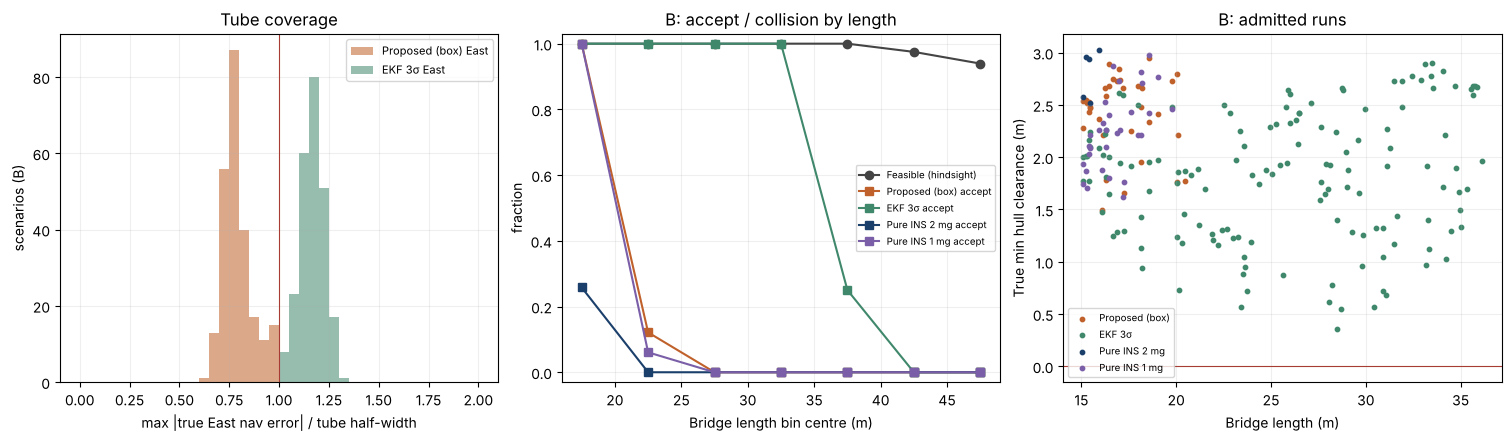

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), layout='constrained')
cols = {'filter': '#c0612b', 'ekf3s': '#40886c', 'ins': '#1b3f6b', 'ins_1mg': '#7a5ea8'}
labels = {'filter': 'Proposed (box)', 'ekf3s': 'EKF 3σ', 'ins': 'Pure INS 2 mg', 'ins_1mg': 'Pure INS 1 mg'}
ax = axes[0]
for m in ('filter', 'ekf3s'):
    ax.hist(B[m + '_cov_ratio_E'], bins=40, range=(0, 2), alpha=.55, color=cols[m], label=labels[m] + ' East')
ax.axvline(1, color='#a83b34', lw=.8)
ax.set(xlabel='max |true East nav error| / tube half-width', ylabel='scenarios (B)', title='Tube coverage')
ax.legend(fontsize=8); ax.grid(alpha=.2)

ax = axes[1]
bins = np.arange(15, 51, 5)
mid = .5*(bins[1:] + bins[:-1])
cut = pd.cut(B['length'], bins, include_lowest=True)
ax.plot(mid, feasible(B, 'filter').groupby(cut, observed=False).mean().values, 'o-', color='#444', label='Feasible (hindsight)')
for m in ('filter', *BASELINES):
    ax.plot(mid, B[m + '_admitted'].fillna(False).astype(bool).groupby(cut, observed=False).mean().values,
            's-', color=cols[m], label=labels[m] + ' accept')
    coll = B[m + '_collided'].astype(bool).groupby(cut, observed=False).mean().values
    if coll.any():
        ax.plot(mid, coll, 'x:', color=cols[m], label=labels[m] + ' collision')
ax.set(xlabel='Bridge length bin centre (m)', ylabel='fraction', title='B: accept / collision by length', ylim=(-.03, 1.03))
ax.legend(fontsize=7); ax.grid(alpha=.2)

ax = axes[2]
for m in ('filter', *BASELINES):
    adm = B[m + '_admitted'].fillna(False).astype(bool)
    ax.scatter(B.loc[adm, 'length'], B.loc[adm, m + '_min_clearance'], s=10, color=cols[m], label=labels[m])
ax.axhline(0, color='#a83b34', lw=.8)
ax.set(xlabel='Bridge length (m)', ylabel='True min hull clearance (m)', title='B: admitted runs')
ax.legend(fontsize=7); ax.grid(alpha=.2)
fig.savefig(FIG/'baselines_mc.png', dpi=200); fig.savefig(FIG/'baselines_mc.pdf')
plt.show()

## INS 器件等级 → 最长可认证桥长（主实验世界，8 m 宽）

纯 INS 的误差界与海流无关但按时间二次增长，结论强烈依赖加速度计零偏等级。
下面只做入口认证，扫描零偏等级与桥长，并与本文（船模辅助 + 确定性误差盒）、EKF 3σ 在同一世界的最长可认证桥长对比。

In [6]:
GRADES = [0.1, 0.25, 0.5, 1.0, 2.0, 3.0, 5.0]   # mg
LS = list(range(9, 61, 3))
path = RES/'ins_grade_map.csv'
if path.exists():
    gm = pd.read_csv(path); print('loading', path.name)
else:
    t0 = time.time()
    jobs = [dict(s=replace(DEFAULT_SCENARIO, length=float(L)), accel_mg=g) for g in GRADES for L in LS]
    jobs += [dict(s=replace(DEFAULT_SCENARIO, length=float(L)), bound_kind=b) for b in ('box', 'ekf') for L in LS]
    out = []
    ins_rows = pmap(ins_gate, jobs[:len(GRADES)*len(LS)], workers=WORKERS)
    ref_rows = pmap(gate_check, jobs[len(GRADES)*len(LS):], workers=WORKERS)
    for kw, r in zip(jobs[len(GRADES)*len(LS):], ref_rows):
        r.update(length=kw['s'].length, width=kw['s'].width, accel_mg=np.nan, nav=kw['bound_kind'])
    for r in ins_rows: r['nav'] = 'ins'
    gm = pd.DataFrame(ins_rows + ref_rows)
    gm.to_csv(path, index=False); print(f'{len(gm)} gate checks in {time.time()-t0:.0f} s')
assert 'error' not in gm or gm['error'].isna().all()
def longest(d):
    ok = d[d['admitted'].astype(bool)]
    return ok['length'].max() if len(ok) else np.nan
ins_lim = gm[gm.nav == 'ins'].groupby('accel_mg').apply(longest).rename('INS longest certified (m)')
ref_lim = gm[gm.nav != 'ins'].groupby('nav').apply(longest)
print(ref_lim.to_dict())
ins_lim.to_frame()

loading ins_grade_map.csv
{'box': 18.0, 'ekf': 33.0}


,INS longest certified (m)
accel_mg,
0.10,27.0
0.25,24.0
0.50,21.0
1.00,18.0
2.00,15.0
3.00,12.0
5.00,9.0


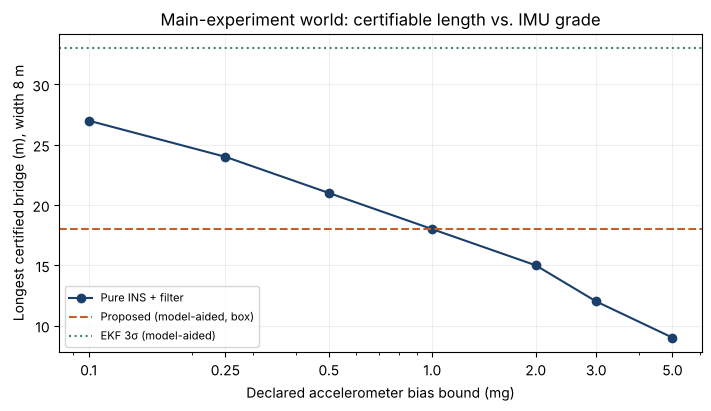

In [7]:
fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
ax.plot(ins_lim.index, ins_lim.values, 'o-', color='#1b3f6b', label='Pure INS + filter')
ax.axhline(ref_lim.get('box', np.nan), color='#c0612b', ls='--', label='Proposed (model-aided, box)')
ax.axhline(ref_lim.get('ekf', np.nan), color='#40886c', ls=':', label='EKF 3σ (model-aided)')
ax.set_xscale('log'); ax.set_xticks(GRADES, [str(g) for g in GRADES])
ax.set(xlabel='Declared accelerometer bias bound (mg)', ylabel='Longest certified bridge (m), width 8 m',
       title='Main-experiment world: certifiable length vs. IMU grade')
ax.grid(alpha=.2); ax.legend(fontsize=8)
fig.savefig(FIG/'ins_grade.png', dpi=200); fig.savefig(FIG/'ins_grade.pdf')
plt.show()

## 结论

数字取自上面的实际运行（统一参数，横荡速度误差界 0.015 m/s）。
**EKF 3σ（同一安全滤波，只换误差管）**
- 放行更多：B 部分 143/240（59.6%），本文方法 35/240（14.6%）；误拒率 39.7% 对 85.2%。主实验世界最长认证（3 m 步长）33 m 对 18 m。
- 在 440 个界内随机世界里，撞墙 0，错误放行 0。
- 但 3σ 管不是界：全程覆盖率 0/440，最大越界 1.38–1.40 倍。放行者最小间隙 0.36 m（B）和 0.65 m（A），本文方法为 1.49 m 和 1.27 m。
- 在最坏世界里它会错误放行不可通过的桥并撞墙（04），超出假设时撞得更多（05）。

**纯 INS 推算 + 安全滤波**
- 2 mg：A 部分 0/200 放行，B 部分 8/240，其中认证丢失 6/8。1 mg：A 部分 200/200 放行，但认证丢失 11/200（5.5%），通过 94.5%；B 部分 33/240，认证丢失 3/33。
- 器件等级决定结果。主实验世界最长可认证桥长：0.1/0.25/0.5/1/2/3/5 mg 对应 27/24/21/18/15/12/9 m；本文船模辅助方法为 18 m，约相当于 1 mg 的 INS。
- 认证丢失的原因是 A3 不成立：滤波器的预测模型仍用船模和**已知**海流，而 INS 估计看得到真实射流造成的漂移，估计偏离预测，桥下某一步找不到通过验证的动作。仿真里认证丢失即终止运行，所以“撞墙 0”是被截断的结果，不能作为 INS 安全的证据。
- 声明的最大水平加速度 1.2 m/s²：首轮检查中制动/后撤之外实测最大 1.11 m/s²，满足假设。

**对论文的意义**：误差界框架可以换入别的导航源（INS 误差盒覆盖 100%），但前提是预测与导航递推一致（A3）。船模辅助导航天然满足这一点，这可以作为选择船模辅助的理由。